# 🛒 Classificação Inteligente de Avaliações de Clientes (Análise de Sentimentos)

## 1. O Problema de Negócio que Estou Resolvendo

Imagine uma loja virtual que vende centenas de produtos todos os dias. Os clientes deixam muitas avaliações: alguns elogiam a entrega rápida, enquanto outros reclamam de defeitos ou atrasos.

Ler todos esses comentários um por um manualmente é humanamente impossível, demorado e muito caro.

**O meu objetivo neste projeto:**
Construir um modelo de Machine Learning que leia qualquer avaliação em português e classifique na hora se ela é **positiva** (elogio) ou **negativa** (reclamação).

**Os benefícios práticos que estou buscando:**
* **Agilidade:** O sistema lê milhares de opiniões em questão de segundos.
* **Socorro rápido ao cliente:** Se alguém deixar uma reclamação grave, o sistema avisa a equipe de suporte imediatamente para resolver a insatisfação antes que vire um cancelamento.
* **Melhoria contínua dos produtos:** O time de produto descobre com facilidade quais itens estão agradando e quais precisam de melhorias.

## 2. Preparando a Minha Caixa de Ferramentas

Antes de começar qualquer análise, eu sempre separo os ingredientes e os instrumentos de trabalho. Aqui no Python, eu instalo e importo todas as bibliotecas necessárias para o projeto.

---
### 🛠️ O que cada célula de código a seguir faz:

* **Célula de instalação do `watermark` (`uv add -q -U watermark`):** 
  Instalo no ambiente a ferramenta `watermark` (usando o `uv`). Eu uso essa ferramenta como uma "etiqueta" para registrar as versões de tudo o que utilizei, garantindo que meu código seja 100% reproduzível no futuro.

* **Célula de importações (`import ...`):**
  Aqui eu trago para o ambiente todas as bibliotecas do meu fluxo:
  * `pandas` e `numpy`: Para manipular e organizar meus dados em formato de tabelas.
  * `re` e `unicodedata`: Para realizar a higienização dos textos (remover acentos, caracteres especiais e pontuações).
  * `matplotlib` e `seaborn`: Para gerar os gráficos da minha análise exploratória.
  * `sklearn` (Scikit-Learn): Para dividir os dados, transformar texto em números com TF-IDF, treinar o modelo e calcular as métricas.
  * `joblib`: Para salvar o meu modelo treinado em um arquivo final.

* **Célula de visualização (`sns.set_style` e `%matplotlib inline`):**
  Configuro o tema dos meus gráficos para um estilo limpo com linhas de grade (`whitegrid`) e garanto que eles apareçam renderizados diretamente aqui no notebook.

* **Célula `%watermark -a ...`:**
  Carimbo no notebook o meu nome como autor do projeto (Lucas Ricardo Borba).

* **Célula `%watermark --iversions`:**
  Exibo as versões exatas de cada biblioteca que acabei de importar.

In [45]:
# Instala o pacote watermark
!uv add -q -U watermark

In [46]:
# Manipulação de dados e visualização
import re
import pandas as pd
import numpy as np
import unicodedata
import seaborn as sns
import matplotlib.pyplot as plt

# Pré-Processamento e Machine Learning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib

In [47]:
# Configurações de visualização
sns.set_style('whitegrid')
%matplotlib inline

In [48]:
%reload_ext watermark
%watermark -a "Lucas Ricardo Borba"

Author: Lucas Ricardo Borba



In [49]:
%watermark --iversions

joblib    : 1.6.0
matplotlib: 3.11.2
numpy     : 2.5.4
pandas    : 3.1.0
re        : 2.2.1
seaborn   : 0.13.2
sklearn   : 1.9.1



## 3. Carregando e Inspecionando os Meus Dados

Com o ambiente pronto, agora eu carrego o arquivo com os comentários dos clientes para entender a estrutura dos dados que vou trabalhar.

---
### 🔍 O que cada célula de código a seguir faz:

* **Célula `nome_arquivo_csv = 'dataset.csv'`:**
  Defino o nome do arquivo numa variável. Faço isso para manter uma boa prática: se o arquivo mudar de nome ou caminho, eu só preciso alterar essa linha.

* **Célula `pd.read_csv(...)`:**
  Leio o arquivo CSV e armazeno tudo num DataFrame do Pandas (`df_dsa`), como se estivesse abrindo uma planilha para trabalhar.

* **Célula `df_dsa.shape`:**
  Verifico as dimensões da minha tabela para saber exatamente quantas linhas (avaliações) e colunas eu tenho em mãos.

* **Célula `df_dsa.head()`:**
  Espio as primeiras 5 linhas para conhecer os nomes das colunas e os primeiros exemplos de comentários.

* **Célula `df_dsa.sample(10)`:**
  Sorteio 10 linhas aleatórias da tabela para verificar a variedade dos textos e não ficar enviesado apenas pelo início do arquivo.

* **Célula `df_dsa.tail()`:**
  Olho as últimas 5 linhas da tabela para me certificar de que os dados do final do arquivo foram carregados perfeitamente.

In [50]:
# Define o nome do arquivo
nome_arquivo_csv = 'dataset.csv'

In [51]:
# Carrega o dataset
df_dsa = pd.read_csv(nome_arquivo_csv)

In [52]:
# Shape
df_dsa.shape

(500, 3)

In [53]:
# Primeiras linhas
df_dsa.head()

,review_id,texto_review,sentimento
0,1,Estou muito feliz com a compra. O cadeira game...,positivo
1,2,NaN,negativo
2,3,Não recomendo. A entrega foi lenta e o celular...,negativo
3,4,O monitor é decepcionante. O suporte ao client...,positivo
4,5,É UM LIVRO OK PELO PRÇEO QUE PAGUEI.,negativo


In [54]:
# Amostra dos dados
df_dsa.sample(10)

,review_id,texto_review,sentimento
95,96,O notebook é de baixa qualidade. O suporte ao ...,negativo
371,372,Simplesmente perfeito! O notebook funciona mui...,positivo
321,322,Amei o cadeira gamer! A qualidade é incrível e...,positivo
65,66,"Excelente cadeira gamer, superou minhas expect...",positivo
59,60,Ótimo custo-benefício. O notebook é muito boa ...,positivo
342,343,Amei o mouse! A qualidade é fantástica e a ent...,positivo
141,142,Ótimo custo-benefício. O cadeira gamer é fantá...,positivo
179,180,A embalagem do fone de ouvido chegou um pouco ...,positivo
311,312,Estou muito impressionado com a compra. O fone...,positivo
120,121,PÉSSIMA EXPERIÊNCIA. O MONITOR QUEBROU NO PRIM...,negativo


In [55]:
# Últimas linhas
df_dsa.tail()

,review_id,texto_review,sentimento
495,496,Odiei o teclado. Qualidade de baixa qualidade ...,negativo
496,497,Estou muito impressionado com a compra. O moni...,positivo
497,498,Não recomendo. A entrega demorou uma eternidad...,negativo
498,499,Estou muito arrependido com esta compra. Dinhe...,negativo
499,500,Ótimo custo-benefício. O cadeira gamer é incrí...,positivo


## 4. Minha Análise Exploratória de Dados (EDA)

Antes de pensar em modelagem, eu assumo o papel de investigador para avaliar a saúde, integridade e características da minha base de dados.

---
### 🔎 O que cada célula de código a seguir faz:

* **Célula `df_dsa.info()`:**
  Gero um raio-X completo da tabela: tipos de dados de cada coluna, contagem de registros preenchidos e uso de memória.

* **Célula `df_dsa.isnull().sum()`:**
  Verifico se existem valores ausentes (nulos) em alguma coluna. Se houver clientes que não escreveram nenhum texto, preciso identificar isso para tratar.

* **Célula do gráfico `sns.countplot(...)`:**
  Crio um gráfico de barras para visualizar a proporção entre avaliações positivas e negativas. Isso me mostra se as classes estão bem balanceadas ou se há disparidade entre elogios e reclamações.

In [56]:
# Info
df_dsa.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   review_id     500 non-null    int64
 1   texto_review  488 non-null    str  
 2   sentimento    500 non-null    str  
dtypes: int64(1), str(2)
memory usage: 11.8 KB


In [57]:
print("\nVerificando valores ausentes:\n")
print(df_dsa.isnull().sum())


Verificando valores ausentes:

review_id        0
texto_review    12
sentimento       0
dtype: int64



Distribuição dos Sentimentos:



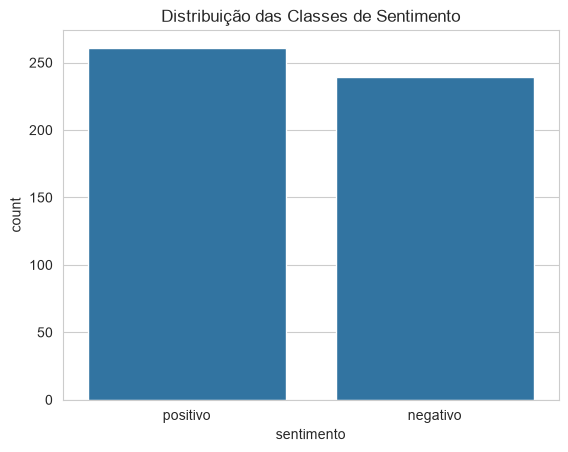

In [58]:
print("\nDistribuição dos Sentimentos:\n")
sns.countplot(x = 'sentimento', data = df_dsa)
plt.title('Distribuição das Classes de Sentimento')
plt.show()

## 5. Limpeza e Higienização dos Textos

Comentários da internet chegam com pontuações exageradas ("ótimo!!!!"), letras maiúsculas misturadas, números e acentos. Para o algoritmo, "Ótimo", "ótimo" e "otimo!" seriam palavras distintas. Por isso, aqui eu construo uma rotina para padronizar todo o texto.

---
### 🧹 O que cada célula de código a seguir faz:

* **Célula `df_dsa.dropna(...)`:**
  Removo as linhas que não possuem texto de avaliação. Como não é possível extrair sentimento do vazio, eu descarto esses registros nulos e exibo quantas linhas restaram.

* **Célula `df_dsa.shape`:**
  Confiro novamente a quantidade de linhas e colunas para confirmar o tamanho exato da minha base após a remoção dos nulos.

* **Célula `df_dsa.head()`:**
  Inspeciono o topo da tabela para garantir que tudo continua no lugar.

* **Célula da função `def dsa_limpa_texto(texto):`:**
  Crio a minha função personalizada de limpeza textual, aplicando 4 etapas:
  1. Converto todo o texto para minúsculas;
  2. Removo acentuação e cedilhas via `unicodedata` (ex.: "não" vira "nao");
  3. Utilizo Expressões Regulares (`re`) para manter apenas letras e espaços, descartando números e símbolos;
  4. Elimino espaços em branco duplicados e espaços soltos nas extremidades.

* **Célula `df_dsa['texto_limpo'] = ...`:**
  Aplico a minha função de limpeza em cada avaliação da base e salvo o resultado em uma nova coluna chamada `texto_limpo`.

* **Célula `df_dsa.head()`:**
  Exibo as primeiras linhas para comparar o texto bruto original com o texto limpo que acabei de gerar.

In [59]:
# Remover linhas com valores ausentes
print(f"\nTamanho original do DataFrame: {len(df_dsa)}")
df_dsa = df_dsa.dropna(subset = ['texto_review'])
print(f"Tamanho do DataFrame após remover nulos: {len(df_dsa)}")


Tamanho original do DataFrame: 500
Tamanho do DataFrame após remover nulos: 488


In [60]:
df_dsa.shape

(488, 3)

In [61]:
df_dsa.head()

,review_id,texto_review,sentimento
0,1,Estou muito feliz com a compra. O cadeira game...,positivo
2,3,Não recomendo. A entrega foi lenta e o celular...,negativo
3,4,O monitor é decepcionante. O suporte ao client...,positivo
4,5,É UM LIVRO OK PELO PRÇEO QUE PAGUEI.,negativo
5,6,Não rceomendo. A entrega atrasou muito e o mon...,positivo


In [62]:
# Função de limpeza de texto 
def dsa_limpa_texto(texto):
    
    """
    Função completa de limpeza de texto:
    1. Converte para minúsculas.
    2. Remove acentos e cedilha.
    3. Remove pontuações, números e caracteres especiais.
    4. Remove espaços extras.
    """
    
    # Garante que o texto não seja nulo (caso haja algum NaN no DataFrame)
    if not isinstance(texto, str):
        return ""

    # --- PASSO 1: Normalizar e remover acentos ---
    # Normaliza para a forma 'NFKD' que separa o caractere da acentuação
    # e depois remove os acentos (Nonspacing Mark)
    texto_sem_acentos = ''.join(c for c in unicodedata.normalize('NFKD', texto) if unicodedata.category(c) != 'Mn')

    # --- PASSO 2: Limpeza com Regex ---
    # Converter para minúsculas
    texto_limpo = texto_sem_acentos.lower()
    
    # Manter apenas letras e espaços. A remoção de acentos já foi feita.
    texto_limpo = re.sub(r'[^a-z\s]', '', texto_limpo)
    
    # Remover espaços extras
    texto_limpo = re.sub(r'\s+', ' ', texto_limpo).strip()
    
    return texto_limpo

In [63]:
# Aplica a função de limpeza
df_dsa['texto_limpo'] = df_dsa['texto_review'].apply(dsa_limpa_texto)

In [64]:
df_dsa.head()

,review_id,texto_review,sentimento,texto_limpo
0,1,Estou muito feliz com a compra. O cadeira game...,positivo,estou muito feliz com a compra o cadeira gamer...
2,3,Não recomendo. A entrega foi lenta e o celular...,negativo,nao recomendo a entrega foi lenta e o celular ...
3,4,O monitor é decepcionante. O suporte ao client...,positivo,o monitor e decepcionante o suporte ao cliente...
4,5,É UM LIVRO OK PELO PRÇEO QUE PAGUEI.,negativo,e um livro ok pelo prceo que paguei
5,6,Não rceomendo. A entrega atrasou muito e o mon...,positivo,nao rceomendo a entrega atrasou muito e o moni...


💡 **Nota sobre a limpeza:** Na função acima utilizei a biblioteca `re` (Expressões Regulares) para localizar e filtrar os caracteres indesejados. Para quem quiser se aprofundar na sintaxe de regex no Python, consultei a documentação oficial em: https://docs.python.org/3/library/re.html

## 6. Engenharia de Atributos: Traduzindo para Números

Algoritmos de Machine Learning operam sobre matemática, não palavras. Portanto, nesta etapa eu traduzo a coluna de sentimento textual para um formato binário numérico que o modelo consiga processar.

---
### 🔢 O que cada célula de código a seguir faz:

* **Célula `df_dsa.head()`:**
  Dou mais uma conferida rápida nas colunas antes de realizar a transformação.

* **Célula `df_dsa['sentimento_label'] = df_dsa['sentimento'].map(...)`:**
  Faço o mapeamento direto: converto "positivo" para o número `1` e "negativo" para o número `0`, criando a coluna `sentimento_label`.

* **Célula `df_dsa[['texto_limpo', 'sentimento_label']].head()`:**
  Exibo apenas as duas colunas essenciais para o modelo: o texto higienizado e o rótulo numérico correspondente (0 ou 1).

In [65]:
df_dsa.head()

,review_id,texto_review,sentimento,texto_limpo
0,1,Estou muito feliz com a compra. O cadeira game...,positivo,estou muito feliz com a compra o cadeira gamer...
2,3,Não recomendo. A entrega foi lenta e o celular...,negativo,nao recomendo a entrega foi lenta e o celular ...
3,4,O monitor é decepcionante. O suporte ao client...,positivo,o monitor e decepcionante o suporte ao cliente...
4,5,É UM LIVRO OK PELO PRÇEO QUE PAGUEI.,negativo,e um livro ok pelo prceo que paguei
5,6,Não rceomendo. A entrega atrasou muito e o mon...,positivo,nao rceomendo a entrega atrasou muito e o moni...


In [66]:
# Mapear o sentimento para valores numéricos (Engenharia de Atributos)
df_dsa['sentimento_label'] = df_dsa['sentimento'].map({'positivo': 1, 'negativo': 0})

In [67]:
print("\nDataFrame após a limpeza e mapeamento:\n")
df_dsa[['texto_limpo', 'sentimento_label']].head()


DataFrame após a limpeza e mapeamento:



,texto_limpo,sentimento_label
0,estou muito feliz com a compra o cadeira gamer...,1
2,nao recomendo a entrega foi lenta e o celular ...,0
3,o monitor e decepcionante o suporte ao cliente...,1
4,e um livro ok pelo prceo que paguei,0
5,nao rceomendo a entrega atrasou muito e o moni...,1


## 7. Divisão dos Dados em Treino e Teste

Para avaliar o modelo de forma justa e evitar que ele apenas decore os dados (overfitting), eu separo o conjunto em duas partes: uma para o aprendizado e outra totalmente isolada para a avaliação final.

---
### 🎯 O que cada célula de código a seguir faz:

* **Célula de definição de `X` e `y`:**
  Defino claramente as minhas variáveis de entrada e saída:
  * `X`: O texto limpo dos reviews (a entrada que o modelo vai ler).
  * `y`: Os rótulos numéricos 0 e 1 (o gabarito verdadeiro do sentimento).

* **Célula `train_test_split(...)`:**
  Faço a partição dos dados:
  * Separo **75%** dos dados para o treino (`X_treino`, `y_treino`);
  * Reservo **25%** dos dados exclusivamente para o teste (`X_teste`, `y_teste`);
  * Uso `stratify = y` para garantir que a proporção entre positivos e negativos permaneça rigorosamente a mesma em ambos os grupos.

In [68]:
# Definir variáveis X (entrada) e y (saída)
X = df_dsa['texto_limpo']
y = df_dsa['sentimento_label']

In [69]:
# Dividir os dados em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size = 0.25, random_state = 42, stratify = y)

## 8. Construindo a Minha Linha de Produção (Pipeline)

Em vez de aplicar cada transformação manualmente a cada nova previsão, eu monto uma esteira automatizada (`Pipeline`).

Dessa forma, qualquer texto que entrar nessa esteira passará automaticamente por todas as etapas de pré-processamento até a previsão final.

---
### ⚙️ O que as próximas duas células de código fazem:

* **Célula de criação do `Pipeline([...])`:**
  Estruturo a minha esteira em 3 fases sequenciais:
  1. `tfidf` (TfidfVectorizer): Converte o texto em vetores numéricos de relevância (TF-IDF), descartando *stop words* comuns em português;
  2. `scaler` (StandardScaler): Normaliza a escala dos atributos com `with_mean = False`, preservando a esparsidade da matriz TF-IDF;
  3. `logreg` (LogisticRegression): O algoritmo classificador de Regressão Logística que tomará a decisão binária (0 ou 1). *(Documentação de referência: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)*.

* **Célula `type(pipeline)`:**
  Verifico se o objeto instanciado é de fato um `Pipeline` oficial do Scikit-Learn.

In [70]:
# Pipeline 
pipeline = Pipeline([
    
    ('tfidf', TfidfVectorizer(stop_words = ['de', 'a', 'o', 'que', 'e', 'do', 'da', 'em', 'um'])),
    
    ('scaler', StandardScaler(with_mean = False)),
    
    ('logreg', LogisticRegression(solver = 'liblinear', random_state = 42, max_iter = 1000)) 
])

In [71]:
type(pipeline)

sklearn.pipeline.Pipeline

### 💡 Como concebi o funcionamento dessa esteira:

Desenhei o meu Pipeline para encadear três tarefas essenciais:

1. **Vetorização (`tfidf`):**
   Mede a importância de cada termo. Palavras com forte carga emotiva (como "excelente" ou "péssimo") ganham peso elevado, enquanto termos neutros ("de", "em", "um") são filtrados.

2. **Padronização (`scaler`):**
   Coloca todos os atributos na mesma escala de variância, evitando que termos mais frequentes dominem o aprendizado do algoritmo.

3. **Classificação (`logreg`):**
   A Regressão Logística calcula a probabilidade e classifica a mensagem como positiva ou negativa.

O maior benefício de usar esse Pipeline é que garanto reprodutibilidade: qualquer novo review passará exatamente pelo mesmo processo sem divergências.

### 8.4. Otimização de Hiperparâmetros (Ajuste Fino)

Para não me contentar com configurações padrão, eu realizo uma busca sistemática pelos melhores hiperparâmetros para extrair a máxima performance do modelo.

---
### 🎛️ O que cada célula de código a seguir faz:

* **Célula `parametros_grid = {...}`:**
  Monto o dicionário com as opções de ajuste que quero testar: número máximo de palavras no TF-IDF, uso de unigramas e bigramas, tipo de regularização da Regressão Logística (`l1_ratio`) e taxa de regularização `C`.

* **Célula `GridSearchCV(...)`:**
  Configuro a busca em grade com validação cruzada (`cv = 5`), utilizando processamento paralelo com todos os núcleos disponíveis (`n_jobs = -1`) e otimizando para a métrica de acurácia (`scoring = 'accuracy'`).

In [72]:
# Definir o grid de hiperparâmetros para otimização
parametros_grid = {
    'tfidf__max_features': [500, 1000, 2000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'logreg__C': [0.1, 1, 10],
    # l1_ratio=0 equivale a penalty='l2'; l1_ratio=1 equivale a penalty='l1'.
    'logreg__l1_ratio': [0, 1],
    'logreg__max_iter': [5000, 6000]
}

In [73]:
# Configurar o GridSearchCV
grid_search = GridSearchCV(
    pipeline,              # Pipeline com as etapas de pré-processamento e modelo
    parametros_grid,       # Dicionário com as combinações de hiperparâmetros a serem testadas
    cv = 5,                # Número de divisões para validação cruzada (5-fold cross-validation)
    n_jobs = -1,           # Usa todos os núcleos disponíveis do processador para acelerar o processo
    scoring = 'accuracy',  # Métrica usada para avaliar o desempenho de cada combinação (aqui, acurácia)
    verbose = 1            # Nível de detalhamento do output durante a execução (1 exibe progresso básico)
)

🔍 **Como funciona a Validação Cruzada (`cv = 5`) que configurei:**
O algoritmo divide os dados de treino em 5 partes iguais. Em cada iteração, ele treina o modelo com 4 partes e valida na 5ª parte restante, repetindo o processo 5 vezes de forma rotativa. Com isso, tenho a garantia de que a performance encontrada é sólida e não fruto de uma divisão favorável dos dados.

### 8.5. Treinamento e Seleção do Melhor Modelo

Nesta etapa eu coloco o computador para processar todas as combinações de parâmetros e identificar a melhor configuração.

---
### 🏋️‍♂️ O que cada célula de código a seguir faz:

* **Célula `grid_search.fit(...)`:**
  Executo o treinamento efetivo com a validação cruzada nos dados de treino (`X_treino`, `y_treino`).

* **Célula `print(grid_search.best_params_)`:**
  Exibo no output os melhores hiperparâmetros encontrados pelo GridSearchCV.

* **Célula `melhor_modelo_dsa = grid_search.best_estimator_`:**
  Extraio e armazeno o modelo campeão já treinado com a melhor configuração.

* **Célula `type(melhor_modelo_dsa)`:**
  Confirmo que o modelo salvo é a esteira completa (`Pipeline`) pronta para uso.

In [74]:
print("\nIniciando o treinamento do modelo com otimização de hiperparâmetros...\n")
grid_search.fit(X_treino, y_treino)


Iniciando o treinamento do modelo com otimização de hiperparâmetros...

Fitting 5 folds for each of 72 candidates, totalling 360 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logreg__C': [0.1, 1, ...], 'logreg__l1_ratio': [0, 1], 'logreg__max_iter': [5000, 6000], 'tfidf__max_features': [500, 1000, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`s

In [75]:
print("\nMelhores hiperparâmetros encontrados:\n")
print(grid_search.best_params_)


Melhores hiperparâmetros encontrados:

{'logreg__C': 0.1, 'logreg__l1_ratio': 1, 'logreg__max_iter': 5000, 'tfidf__max_features': 500, 'tfidf__ngram_range': (1, 1)}


In [76]:
# Obter o melhor modelo
melhor_modelo_dsa = grid_search.best_estimator_

In [77]:
type(melhor_modelo_dsa)

sklearn.pipeline.Pipeline

## 9. Avaliando o Desempenho do Meu Modelo com Dados de Teste

Agora eu submeto o meu modelo campeão ao teste definitivo: fazer previsões sobre o conjunto de teste (25% dos dados) que ele nunca viu durante o treinamento.

---
### 📊 O que cada célula de código a seguir faz:

* **Célula `y_pred = melhor_modelo_dsa.predict(X_teste)`:**
  Gero as previsões de sentimento para os dados de teste e guardo o resultado em `y_pred`.

* **Célula de cálculo das métricas (`accuracy_score` e `classification_report`):**
  Calculo a acurácia global e gero o relatório detalhado de métricas comparando `y_pred` com o gabarito real `y_teste`.

* **Célula de impressão dos resultados:**
  Imprimo a acurácia formatada em percentual e o relatório completo de classificação.

* **Célula da Matriz de Confusão (`confusion_matrix` e heatmap):**
  Gero o mapa de calor da Matriz de Confusão para inspecionar visualmente os acertos (Verdadeiros Positivos e Verdadeiros Negativos) e eventuais erros de classificação.

In [78]:
# Previsões no conjunto de teste
y_pred = melhor_modelo_dsa.predict(X_teste)

In [79]:
# Calcular as métricas de avaliação
acuracia = accuracy_score(y_teste, y_pred)
report = classification_report(y_teste, y_pred, target_names = ['Negativo', 'Positivo'])

In [80]:
print(f"\nAcurácia do Modelo: {acuracia:.2%}\n")
print("Relatório de Classificação:\n")
print(report)


Acurácia do Modelo: 81.15%

Relatório de Classificação:

              precision    recall  f1-score   support

    Negativo       0.80      0.81      0.80        58
    Positivo       0.83      0.81      0.82        64

    accuracy                           0.81       122
   macro avg       0.81      0.81      0.81       122
weighted avg       0.81      0.81      0.81       122



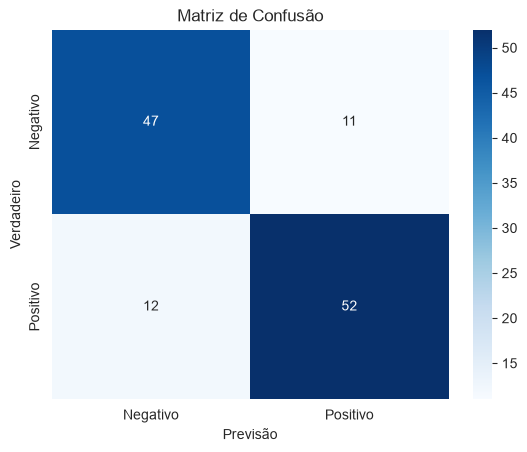

In [81]:
# Visualizar a Matriz de Confusão
cm = confusion_matrix(y_teste, y_pred)
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues',
            xticklabels = ['Negativo', 'Positivo'],
            yticklabels = ['Negativo', 'Positivo'])
plt.xlabel('Previsão')
plt.ylabel('Verdadeiro')
plt.title('Matriz de Confusão')
plt.show()

### 🎓 Como interpreto as métricas do meu modelo:

* **1. Acurácia (Accuracy):**
  Representa a taxa geral de acertos do modelo sobre o total de avaliações avaliadas.

* **2. Precisão (Precision):**
  Dos comentários que meu modelo classificou como positivos, quantos eram de fato elogios reais. Alta precisão evita classificar uma reclamação indevidamente como elogio.

* **3. Recall (Sensibilidade):**
  De todas as reclamações reais dos clientes, quantas o meu modelo conseguiu detectar. **Para mim, esta é a métrica mais crítica de negócio:** um recall alto na classe negativa garante que praticamente nenhuma crítica passe despercebida pelo time de suporte.

* **4. F1-Score:**
  A média harmônica entre precisão e recall, que me indica se o modelo está equilibrado em ambas as classes.

* **5. Suporte (Support):**
  O número real de ocorrências de cada classe no conjunto de teste.

---
### 💾 O que as próximas duas células de código fazem:

* **Célula `joblib.dump(...)`:**
  Como estou satisfeito com o resultado do modelo, eu o serializo e salvo em disco no arquivo `modelo_sentimento_dsa_v1.joblib` para poder reutilizá-lo sem precisar treinar tudo novamente.

* **Célula `del melhor_modelo_dsa`:**
  Removo intencionalmente o objeto da memória RAM para provar, na seção seguinte, que consigo recarregar o modelo diretamente do arquivo salvo.

In [82]:
# Se estivermos satisfeitos com a performance do modelo, salvamos em disco
joblib.dump(melhor_modelo_dsa, 'modelo_sentimento_dsa_v1.joblib')

['modelo_sentimento_dsa_v1.joblib']

In [83]:
# Pode deletar o modelo treinado e removê-lo da memória
del melhor_modelo_dsa

📌 **Nota sobre a transição para MLOps:**
Aqui encerro a fase clássica de Ciência de Dados (análise, limpeza, modelagem e validação). A partir deste ponto, assumo o papel de Engenharia de Machine Learning (MLOps) para colocar o modelo empacotado à disposição de novas aplicações.

## 10. MLOps: Colocando o Meu Modelo em Produção (Deploy)

Nesta etapa final, simulo o ambiente produtivo: leio o modelo salvo em disco e crio uma função de inferência para classificar novos reviews em tempo real.

---
### 🚀 O que cada célula de código a seguir faz:

* **Célula `joblib.load(...)`:**
  Carrego o modelo salvo do disco (`modelo_sentimento_dsa_v1.joblib`) de volta para a memória.

* **Célula `type(modelo_dsa_deploy)`:**
  Confirmo que o artefato desserializado é a esteira completa (`Pipeline`) intacta.

* **Célula `novos_reviews = [...]`:**
  Defino uma lista com 4 avaliações inéditas (elogios e reclamações) para simular comentários recém-chegados no site.

* **Célula da função `def dsa_prever_sentimento(reviews):`:**
  Implemento a minha função de inferência: ela recebe os textos, executa a previsão através do pipeline carregado, mapeia os valores numéricos de volta para os rótulos "Positivo" e "Negativo" e exibe o resultado formatado.

* **Célula `dsa_prever_sentimento(novos_reviews)`:**
  Executo a função com as novas avaliações e exibo as classificações geradas pelo modelo!

In [84]:
# Carregar o modelo a partir do disco
modelo_dsa_deploy = joblib.load('modelo_sentimento_dsa_v1.joblib')

In [85]:
type(modelo_dsa_deploy)

sklearn.pipeline.Pipeline

In [86]:
# Criar novos dados para simular o uso em produção
novos_reviews = [
    "A bateria do celular não dura nada, péssima compra.",
    "Chegou antes do prazo e o produto é de ótima qualidade! Estou muito feliz.",
    "O serviço de atendimento foi rápido e eficiente.",
    "Não recomendo, veio faltando peças e a cor estava errada."
]

In [87]:
# Função para prever o sentimento de novos reviews 
def dsa_prever_sentimento(reviews):
    
    """
    Recebe uma lista de textos de review e retorna a previsão de sentimento.
    O objeto 'melhor_modelo_dsa' (pipeline) cuida de todos os passos internos.
    """
    
    # 1. 'reviews' entra no pipeline
    # 2. TF-IDF é aplicado internamente
    # 3. StandardScaler é aplicado internamente
    # 4. LogisticRegression faz a previsão
    previsoes = modelo_dsa_deploy.predict(reviews)
    
    # Mapeia o resultado numérico de volta para texto
    sentimentos = ['Negativo' if p == 0 else 'Positivo' for p in previsoes]
    
    # Exibe os resultados
    for review, sentimento in zip(reviews, sentimentos):
        print(f"\nReview: '{review}'\nSentimento Previsto: {sentimento}\n---")

In [88]:
# Executar a função de deploy com os novos dados
print("\n--- Iniciando Classificação de Novos Reviews (Deploy com Pipeline Completo) ---\n")
dsa_prever_sentimento(novos_reviews)


--- Iniciando Classificação de Novos Reviews (Deploy com Pipeline Completo) ---


Review: 'A bateria do celular não dura nada, péssima compra.'
Sentimento Previsto: Negativo
---

Review: 'Chegou antes do prazo e o produto é de ótima qualidade! Estou muito feliz.'
Sentimento Previsto: Positivo
---

Review: 'O serviço de atendimento foi rápido e eficiente.'
Sentimento Previsto: Negativo
---

Review: 'Não recomendo, veio faltando peças e a cor estava errada.'
Sentimento Previsto: Negativo
---


🎉 **Projeto Concluído com Sucesso!**

Desenvolvi e validei uma solução completa de NLP e Machine Learning: desde a ingestão e limpeza dos dados brutos, passando pelo treinamento de um classificador de sentimentos de alta precisão, até o empacotamento e deploy para inferência em produção.

O resultado é um modelo pronto para automatizar a triagem de feedbacks e apoiar as equipes de atendimento e produto na tomada de decisões ágeis!

# Fim do Projeto ✨